# Масштаб после дообучения

Четыре графика: вероятность H, вероятность с поправкой на доноров, RSA по слоям и локализация сходства.
Используются только модели и вероятности из `results/letters_scale_val100`.

In [1]:
from pathlib import Path
import json, hashlib, sys, time
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'results' / 'letters_scale_val100'
OUT = RESULTS / 'analysis'
assert RESULTS.is_dir(), 'Сначала завершите дообучение в letters_training.ipynb.'
OUT.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from model import DeiTTiny

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})

def savefig(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=170, bbox_inches='tight')
    display(fig)
    plt.close(fig)

runs = [f'big_{n:02d}' for n in (0, 1, 5, 10, 15, 20, 25)]
counts = np.array([int(run[-2:]) for run in runs])
summary, h_tests = {}, {}
for run, count in zip(runs, counts):
    with np.load(RESULTS / f'{run}_probabilities.npz', allow_pickle=False) as z:
        classes, donors = z['classes'].tolist(), z['donors'].tolist()
        h = classes.index('H')
        labels, heights = z['labels'], z['heights']
        probabilities = z['probabilities'][-1].astype(np.float64)
        small = heights == 64
        large_h = (heights == 128) & (labels == h)
        assert classes == list('ABCDEFGHIJKLMNOPQRSTUVWXYZ') and len(donors) == count
        assert 'H' not in donors and large_h.sum() == 256 and small.sum() == 26 * 256
        assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(1), 1, atol=2e-6)
        ph = probabilities[large_h]
        remaining = np.array([c not in donors for c in classes])
        mass = ph[:, remaining].sum(1)
        assert np.all(mass > 0)
        adjusted = ph[:, h] / mass * remaining.sum() / len(classes)
        summary[run] = dict(epoch=int(z['epochs'][-1]), donors=donors,
                            raw=float(ph[:, h].mean()), adjusted=float(adjusted.mean()),
                            remaining_mass=float(mass.mean()),
                            recall=float((ph.argmax(1) == h).mean()),
                            small_accuracy=float((probabilities[small].argmax(1) == labels[small]).mean()))
        h_tests[run] = (z['shifts'][large_h].copy(), ph.copy())
    checkpoint = torch.load(RESULTS / f'{run}.pt', map_location='cpu', weights_only=True)
    assert checkpoint['val_target_met'], f'{run}: дообучение ещё не достигло 100% validation.'
    assert int(checkpoint['epoch']) == summary[run]['epoch']
    assert checkpoint['letters'] == ''.join(classes) and list(checkpoint['donors']) == donors
    del checkpoint

print('Доноры | эпоха | accuracy small | recall большой H | средняя p(H)')
for run, count in zip(runs, counts):
    s = summary[run]
    print(f"{count:6d} | {s['epoch']:5d} | {s['small_accuracy']:14.4%} | {s['recall']:16.2%} | {s['raw']:.8f}")

Доноры | эпоха | accuracy small | recall большой H | средняя p(H)
     0 |    91 |      100.0000% |            0.00% | 0.00004155
     1 |   100 |      100.0000% |            0.00% | 0.00000045
     5 |   172 |      100.0000% |            0.00% | 0.00029374
    10 |    90 |      100.0000% |            0.00% | 0.00058047
    15 |   185 |       99.9850% |            0.00% | 0.00002781
    20 |    95 |      100.0000% |            0.00% | 0.00395723
    25 |   100 |       99.9700% |            0.00% | 0.00055846


## 1 Уверенность в H

Средняя `p(H)` по **всем 256** изображениям большой H, включая ошибочные ответы.
Точки соответствуют последним сохранённым весам. Это вероятность правильного класса, а не recall.

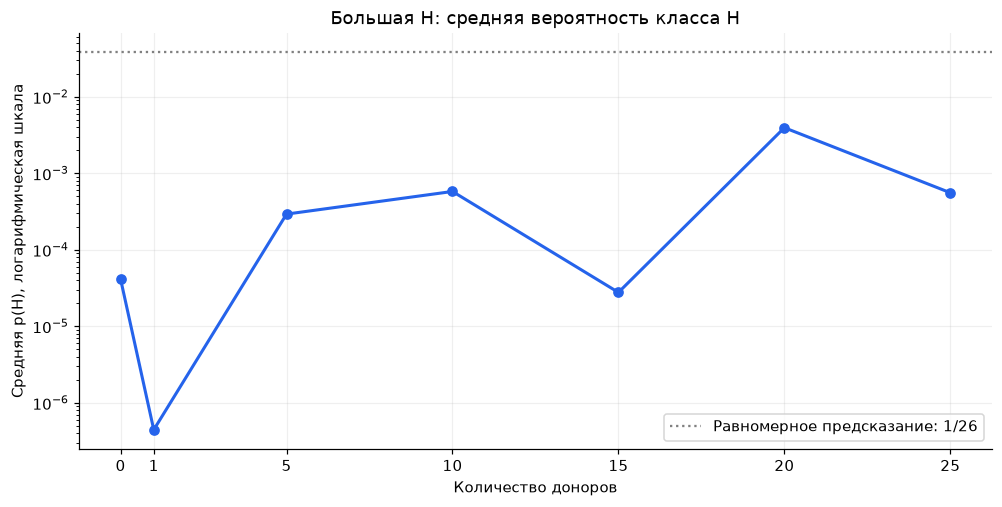

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.plot(counts, [summary[r]['raw'] for r in runs], 'o-', color='#2563eb', lw=2)
ax.axhline(1 / 26, color='gray', ls=':', label='Равномерное предсказание: 1/26')
ax.set(title='Большая H: средняя вероятность класса H', xlabel='Количество доноров',
       ylabel='Средняя p(H), логарифмическая шкала', xticks=counts, yscale='log')
ax.grid(alpha=.2)
ax.legend()
savefig(fig, 'h_confidence')

## 2 Уверенность с поправкой на доноров

Для каждого изображения: `score = p(H) / sum(p(не-доноров)) × (26 − n) / 26`, затем среднее по изображениям.
Прямое суммирование знаменателя численно устойчивее, чем `1 − sum(p(доноров))`.
При равномерном распределении среди оставшихся классов score равен `1/26`.
При **n = 25** остаётся только H, поэтому score всегда равен `1/26`: эта точка вырождена.
Поправка учитывает число оставшихся классов, а не число тестовых изображений. Рост score может происходить
из-за подавления остальных не-доноров даже при низкой исходной p(H) и нулевом recall.

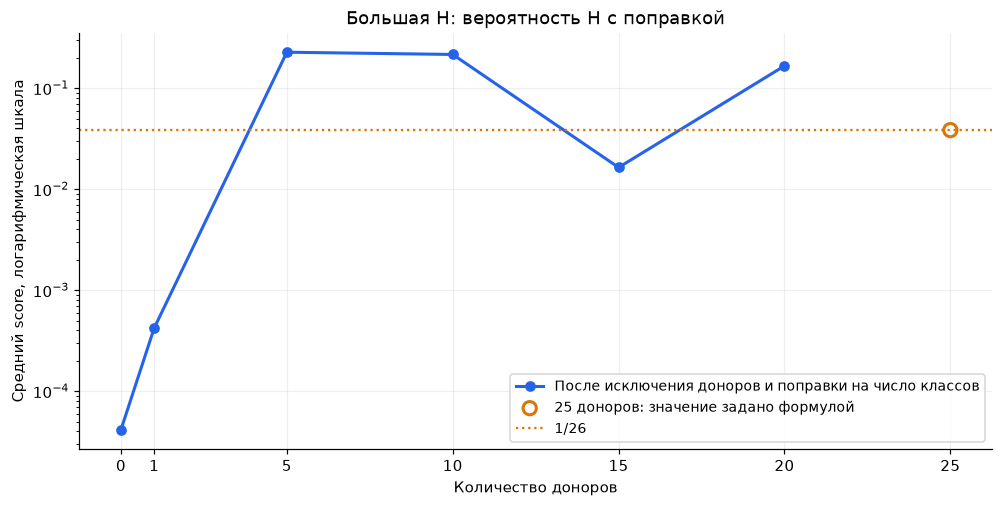

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
values = np.array([summary[r]['adjusted'] for r in runs])
regular = counts < 25
ax.plot(counts[regular], values[regular], 'o-', color='#2563eb', lw=2,
        label='После исключения доноров и поправки на число классов')
ax.scatter(counts[~regular], values[~regular], s=75, facecolors='none',
           edgecolors='#d97706', linewidths=2, label='25 доноров: значение задано формулой')
ax.axhline(1 / 26, color='#d97706', ls=':', label='1/26')
ax.set(title='Большая H: вероятность H с поправкой', xlabel='Количество доноров',
       ylabel='Средний score, логарифмическая шкала', xticks=counts, yscale='log')
ax.grid(alpha=.2)
ax.legend(fontsize=9)
savefig(fig, 'h_confidence_adjusted')

## 3 RSA между размерами по слоям

В прежнем анализе снимался **CLS после каждого из 12 TransformerBlock** (после обоих residual-прибавлений)
и **CLS после финального LayerNorm** перед классификатором — всего 13 точек. Отдельные головы не сравнивались.
Теперь добавлены **26 выходных логитов**. Решающая голова здесь — один `Linear(192, 26)` после LayerNorm;
внутренних скрытых слоёв в ней нет.

Для каждого места: средние активации по 64 положениям → отдельное центрирование по 26 буквам для каждого
размера → cosine-distance между буквами → корреляция Спирмена по 325 парам.
Те же 64 смещения используются для всех букв обоих размеров и всех моделей; они взяты из test больших букв.
Часть этих координат встречалась в train маленьких букв: это **согласованная диагностическая выборка**,
а основной test выше остаётся отдельной оценкой качества.

RSA сравнивает геометрию, не доказывает механизм или правильное распознавание H. Контроль — та же сеть
до обучения с seed = 42. Кеш пересчитывается, если изменились веса, модель, данные или методика.

In [4]:
data_path = ROOT / 'data' / 'letters.pt'
data = torch.load(data_path, map_location='cpu', weights_only=True)
LETTERS, H_INDEX = data['letters'], data['letters'].index('H')
N_POS, BATCH = 64, 32
rng = np.random.default_rng(20261103)
paired_shifts = data['shift_pools'][1]['test'][rng.choice(256, N_POS, replace=False)]
for xmin, xmax, ymin, ymax in data['shift_bounds']:
    assert ((paired_shifts[:, 0] >= xmin) & (paired_shifts[:, 0] <= xmax)).all()
    assert ((paired_shifts[:, 1] >= ymin) & (paired_shifts[:, 1] <= ymax)).all()
labels_probe = torch.arange(26).repeat_interleave(2 * N_POS)
sizes_probe = torch.arange(2).repeat_interleave(N_POS).repeat(26)
shifts_probe = paired_shifts.repeat(52, 1)
layers = [f'B{i}' for i in range(1, 13)] + ['LN', 'logits']
UPPER = np.triu_indices(26, 1)

def ranks(x):
    _, inverse, counts_ = np.unique(x, return_inverse=True, return_counts=True)
    ends = np.cumsum(counts_)
    return ((ends - counts_ + ends - 1) / 2)[inverse]

def corr(a, b):
    a, b = a - a.mean(), b - b.mean()
    norm = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / norm) if norm > 1e-12 else np.nan

def rdm(x):
    x = x.astype(np.float64) - x.mean(0, keepdims=True)
    norms = np.linalg.norm(x, axis=1, keepdims=True)
    if (norms <= 1e-12).any():
        return np.full((26, 26), np.nan)
    x = x / norms
    return 1 - x @ x.T

def rsa(a, b):
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        return np.nan
    return corr(ranks(a[UPPER]), ranks(b[UPPER]))

def component_similarity(features):
    # [letter, size, position, component]
    a, b = features[:, 0].astype(np.float64), features[:, 1].astype(np.float64)
    ac, bc = a - a.mean(0), b - b.mean(0)
    va, vb = (ac * ac).mean(0), (bc * bc).mean(0)
    floor = 1e-12 * np.maximum(1, np.maximum((a * a).mean(0), (b * b).mean(0)))
    valid = (va > floor) & (vb > floor)
    values = np.zeros_like(va)
    np.divide((ac * bc).mean(0), np.sqrt(va * vb), out=values, where=valid)
    n = valid.sum(0)
    result = np.full(features.shape[-1], np.nan)
    np.divide((values * valid).sum(0), n, out=result, where=n >= .9 * N_POS)
    return result, np.stack([va.mean(0), vb.mean(0)])

def shifted_batch(labels, sizes, shifts, templates):
    device = templates.device
    source = templates[labels.to(device), sizes.to(device)]
    shifts = shifts.to(device, dtype=torch.long)
    batch, channels, height, width = source.shape
    x = torch.arange(width, device=device)[None, None, :] - shifts[:, 0, None, None]
    y = torch.arange(height, device=device)[None, :, None] - shifts[:, 1, None, None]
    valid = (x >= 0) & (x < width) & (y >= 0) & (y < height)
    indices = (y.clamp(0, height-1) * width + x.clamp(0, width-1)).reshape(batch, 1, -1)
    shifted = source.flatten(2).gather(2, indices).reshape_as(source)
    return shifted.masked_fill(~valid[:, None], 0).expand(-1, 3, -1, -1)

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

signature = json.dumps(dict(method='cls_heads_v1', seed=42,
                           model=file_hash(ROOT / 'model.py'), data=file_hash(data_path),
                           shifts=paired_shifts.tolist(),
                           checkpoints={r: file_hash(RESULTS / f'{r}.pt') for r in runs}), sort_keys=True)
cache_path = OUT / 'compact_representations.npz'

In [5]:
representation_runs = ['initial'] + runs
representations = {}
if cache_path.exists():
    with np.load(cache_path, allow_pickle=False) as z:
        if str(z['signature'].item()) == signature:
            for run in representation_runs:
                prefix = run + '__'
                representations[run] = {k[len(prefix):]: z[k].copy() for k in z.files if k.startswith(prefix)}

if len(representations) != len(representation_runs):
    assert torch.cuda.is_available(), 'Для пересчёта активаций нужна CUDA.'
    torch.set_num_threads(2)
    device = torch.device('cuda')
    templates = data['images'].to(device, dtype=torch.float32).div(255)
    representations = {}
    for run in representation_runs:
        started = time.perf_counter()
        torch.manual_seed(42)
        model = DeiTTiny(num_classes=26).to(device).eval()
        if run != 'initial':
            checkpoint = torch.load(RESULTS / f'{run}.pt', map_location='cpu', weights_only=True)
            assert checkpoint['letters'] == LETTERS
            assert checkpoint['val_target_met'], f'{run}: validation ещё не равна 100%.'
            assert int(checkpoint['epoch']) == summary[run]['epoch']
            assert list(checkpoint['donors']) == summary[run]['donors']
            model.load_state_dict(checkpoint['state_dict'], strict=True)
        captured, handles = {}, []
        def capture(key):
            def hook(module, inputs, output):
                captured[key] = output[:, 0].detach()
            return hook
        for i, block in enumerate(model.blocks):
            handles.append(block.register_forward_hook(capture(f'block_{i}')))
            for j, head in enumerate(block.attention.heads):
                handles.append(head.register_forward_hook(capture(f'head_{i}_{j}')))
        handles.append(model.norm.register_forward_hook(capture('norm')))
        block_chunks, head_chunks, logit_chunks = [], [], []
        try:
            with torch.inference_mode():
                for start in range(0, len(labels_probe), BATCH):
                    captured.clear()
                    x = shifted_batch(labels_probe[start:start+BATCH], sizes_probe[start:start+BATCH],
                                      shifts_probe[start:start+BATCH], templates)
                    logits = model(x)
                    block_chunks.append(torch.stack([captured[f'block_{i}'] for i in range(12)] +
                                                    [captured['norm']], dim=1).cpu().numpy())
                    head_chunks.append(torch.stack([captured[f'head_{i}_{j}'] for i in range(12)
                                                   for j in range(3)], dim=1).cpu().numpy())
                    logit_chunks.append(logits.cpu().numpy())
        finally:
            for handle in handles:
                handle.remove()
        blocks = np.concatenate(block_chunks).reshape(26, 2, N_POS, 13, 192).transpose(3, 0, 1, 2, 4)
        heads = np.concatenate(head_chunks).reshape(26, 2, N_POS, 12, 3, 64).transpose(3, 4, 0, 1, 2, 5)
        logits = np.concatenate(logit_chunks).reshape(26, 2, N_POS, 26)
        assert np.isfinite(blocks).all() and np.isfinite(heads).all() and np.isfinite(logits).all()
        layer_rsa = []
        for features in list(blocks) + [logits]:
            means = features.mean(2)
            layer_rsa.append(rsa(rdm(means[:, 0]), rdm(means[:, 1])))
        head_pairs = np.empty((12, 3, 3))
        head_components = np.empty((12, 3, 64))
        for i in range(12):
            distances = [[rdm(heads[i, j, :, size].mean(1)) for size in range(2)] for j in range(3)]
            for j in range(3):
                head_components[i, j], _ = component_similarity(heads[i, j])
                for k in range(3):
                    head_pairs[i, j, k] = rsa(distances[j][0], distances[k][1])
        finite = np.isfinite(head_components)
        head_similarity = np.full((12, 3), np.nan)
        np.divide(np.where(finite, head_components, 0).sum(2), finite.sum(2),
                  out=head_similarity, where=finite.sum(2) > 0)
        cls_similarity, cls_variance = component_similarity(blocks[-1])
        weight_h = model.classifier.weight[H_INDEX].detach().cpu().numpy().copy()
        h_contributions = blocks[-1, H_INDEX].mean(1) * weight_h
        error = 0.
        if run != 'initial':
            saved_shifts, expected_all = h_tests[run]
            indices = [np.flatnonzero((saved_shifts == s.numpy()).all(1)).item() for s in paired_shifts]
            expected = expected_all[indices]
            actual = torch.from_numpy(logits[H_INDEX, 1]).softmax(-1).numpy()
            error = float(np.abs(actual - expected).max())
            assert np.allclose(actual, expected, atol=3e-5, rtol=3e-4), (run, error)
        representations[run] = dict(rsa=np.array(layer_rsa), head_pair_rsa=head_pairs,
                                    head_component_correlation=head_components, head_similarity=head_similarity,
                                    cls_similarity=cls_similarity, cls_variance=cls_variance,
                                    weight_h=weight_h, h_contributions=h_contributions,
                                    max_probability_error=np.array(error))
        print(f"{run}: RSA LN={layer_rsa[-2]:.3f}; {time.perf_counter()-started:.1f} сек", flush=True)
        del model, captured, block_chunks, head_chunks, logit_chunks, blocks, heads, logits
        torch.cuda.empty_cache()
    arrays = {f'{run}__{key}': value for run, result in representations.items() for key, value in result.items()}
    np.savez_compressed(cache_path, signature=np.array(signature), paired_shifts=paired_shifts.numpy(),
                        layers=np.array(layers), **arrays)
    del templates
    torch.cuda.empty_cache()
else:
    print('Активации: кеш соответствует текущим весам, модели, данным и смещениям.')

initial: RSA LN=0.979; 3.6 сек
big_00: RSA LN=0.102; 3.4 сек
big_01: RSA LN=0.054; 3.3 сек
big_05: RSA LN=-0.012; 3.5 сек
big_10: RSA LN=0.179; 3.3 сек
big_15: RSA LN=0.504; 3.3 сек
big_20: RSA LN=0.562; 3.3 сек
big_25: RSA LN=0.846; 3.3 сек


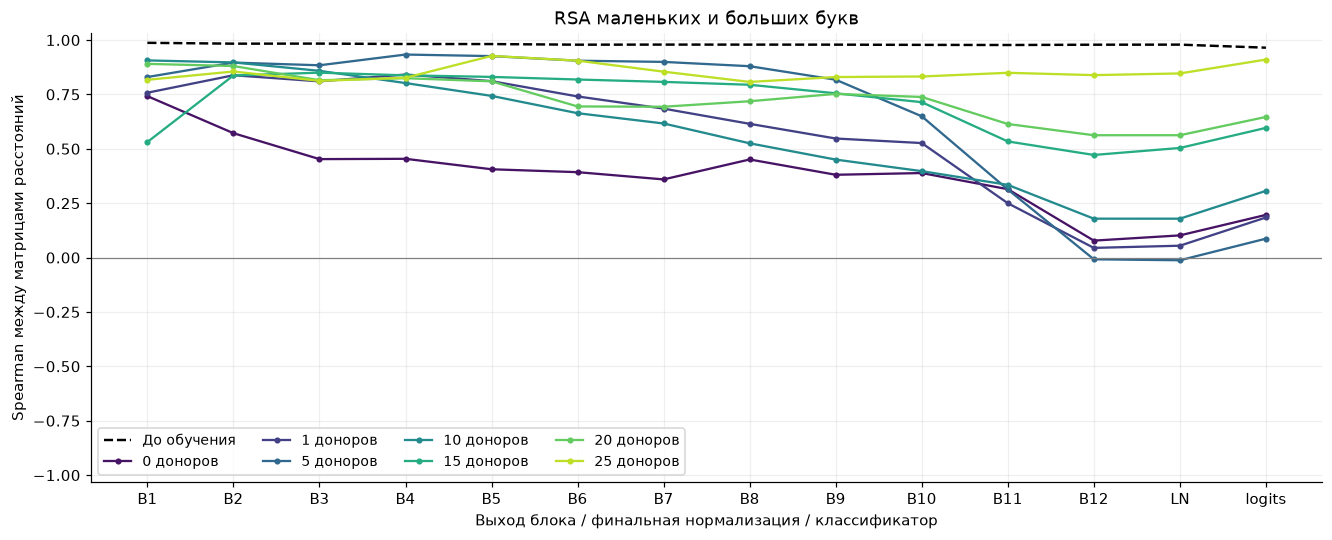

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
xx = np.arange(len(layers))
ax.plot(xx, representations['initial']['rsa'], '--', color='black', lw=1.6, label='До обучения')
for run, count, color in zip(runs, counts, plt.cm.viridis(np.linspace(.05, .9, len(runs)))):
    ax.plot(xx, representations[run]['rsa'], 'o-', markersize=3, color=color, label=f'{count} доноров')
ax.set(title='RSA маленьких и больших букв', xlabel='Выход блока / финальная нормализация / классификатор',
       ylabel='Spearman между матрицами расстояний', xticks=xx, xticklabels=layers, ylim=(-1.03, 1.03))
ax.axhline(0, color='gray', lw=.8)
ax.grid(alpha=.2)
ax.legend(ncol=4, fontsize=9)
savefig(fig, 'rsa_layers')

## 4 Локализация сходства ответов

**Слева:** для каждой головы берём CLS-выход `attention @ V` **до объединения голов и выходной проекции**.
Для каждой компоненты и каждого положения считаем Pearson между её 26 ответами на маленькие буквы
и 26 ответами на большие. Затем усредняем по положениям и компонентам головы.
Компонента учитывается, если её дисперсия по буквам выше численного порога на обоих размерах хотя бы
в 90% положений; постоянные компоненты помечаются `NaN`, а не идеальным сходством.
Высокое значение означает сохранение профиля ответов на классы, но не равенство амплитуд.

**В центре:** RSA для пар «голова i на маленьких → голова j на больших» выбранного блока.
Сначала усредняем активации по тем же 64 положениям. Диагональ сравнивает одну голову с собой,
остальные клетки — геометрию разных голов; они не означают связь или передачу информации между головами.

**Справа:** та же покомпонентная корреляция для 192 признаков CLS после финального LayerNorm.
Сетка 12×16 — только раскладка индексов `j = 16 × строка + столбец`, не пространственная карта изображения.
В таблице ниже — восемь компонент с наибольшей корреляцией, их дисперсия по буквам, вес выхода H
и средние вклады `w_H[j] × z[j]` в логит H. Корреляция этих вкладов совпадает с корреляцией z при
ненулевом весе, поэтому отдельной метрикой она не называется; bias в индивидуальные вклады не входит.
Это вклады в абсолютный логит H, а не в вероятность H или выбор класса. Для сравнения с классом k
важна разность логитов: `(w_H − w_k) · z + b_H − b_k`.
Покомпонентная корреляция зависит от базиса: низкое значение не исключает общий сигнал
в линейных или нелинейных комбинациях каналов.

Центрирование по буквам убирает общий уровень ответа, включая возможный общий сигнал масштаба,
но **не устраняет** всю зависимость от площади и занятости патчей. Это локализация описательного сходства,
а не доказательство «узлов понимания масштаба». Отбор лучших компонент здесь поисковый;
для причинного вывода нужны отдельные проверки вмешательствами.

Профили и корреляции здесь рассчитываются по всем 26 буквам. При 25 донорах большинство классов
уже встречались большими в обучении; эта локализация не изолирует перенос на исключённую H.
Даже сильное общее сходство требует отдельной проверки поведения и вмешательств именно для H.


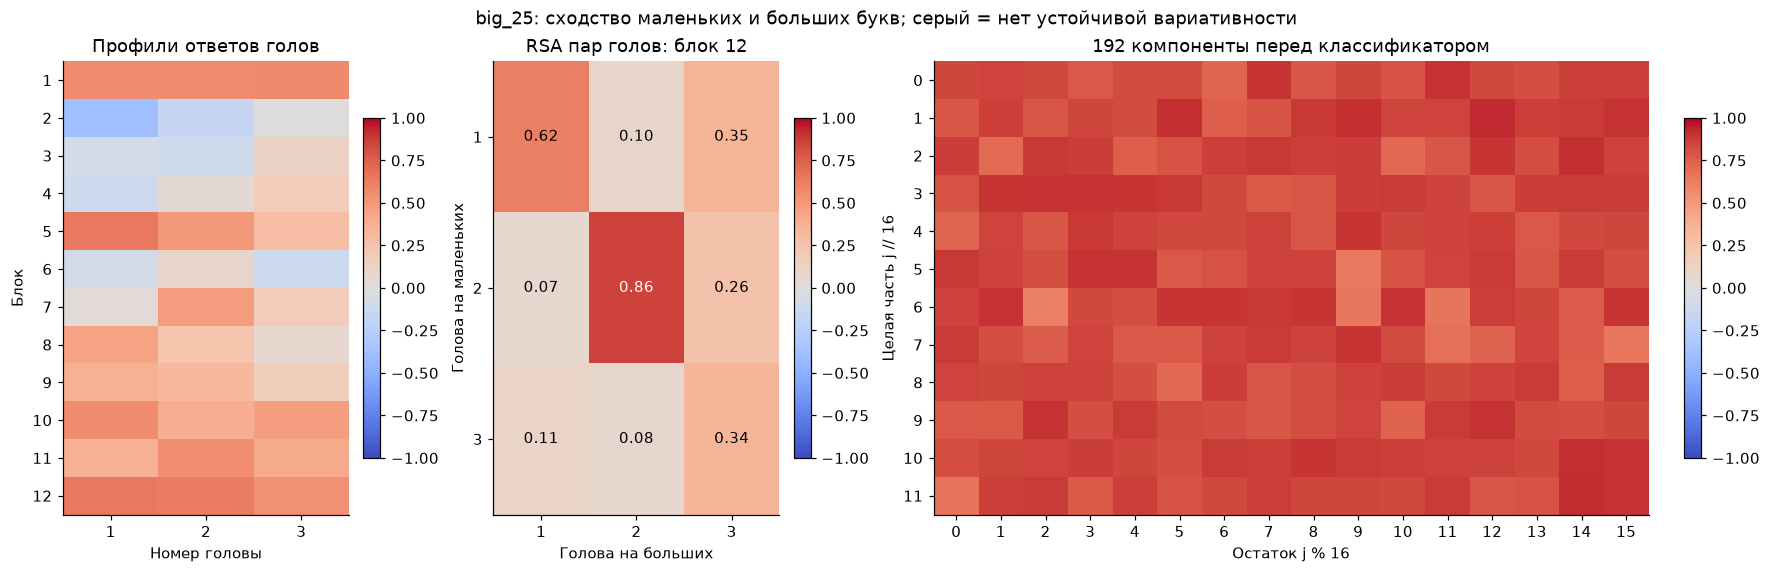

| Компонента | Pearson | Var small | Var large | Вес H | Вклад на H64 | Вклад на H128 |
|---:|---:|---:|---:|---:|---:|---:|
| 28 | 0.924 | 2.851 | 3.154 | 0.02014 | 0.01707 | 0.04223 |
| 190 | 0.914 | 2.155 | 1.842 | 0.00316 | -0.0007395 | 0.001148 |
| 25 | 0.910 | 1.546 | 1.698 | 0.07844 | 0.1424 | 0.1403 |
| 174 | 0.909 | 4.483 | 5.448 | 0.01243 | 0.009543 | 0.03288 |
| 21 | 0.907 | 1.69 | 1.692 | -0.02882 | 0.0327 | 0.006102 |
| 46 | 0.906 | 2.823 | 3.24 | -0.04611 | 0.04956 | 0.14 |
| 51 | 0.905 | 1.944 | 1.794 | 0.03189 | 0.03187 | -0.005249 |
| 175 | 0.905 | 3.022 | 3.005 | -0.04966 | 0.05578 | 0.0379 |

In [7]:
SELECTED_RUN = 'big_25'
SELECTED_BLOCK = 12
assert SELECTED_RUN in representations and 1 <= SELECTED_BLOCK <= 12
result = representations[SELECTED_RUN]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.1), layout='constrained',
                         gridspec_kw={'width_ratios': [1, 1, 2.5]})
cmap = plt.get_cmap('coolwarm').copy()
cmap.set_bad('#d1d5db')
matrices = [result['head_similarity'], result['head_pair_rsa'][SELECTED_BLOCK - 1],
            result['cls_similarity'].reshape(12, 16)]
for ax, matrix in zip(axes, matrices):
    im = ax.imshow(matrix, cmap=cmap, vmin=-1, vmax=1, aspect='auto')
    fig.colorbar(im, ax=ax, shrink=.75)
axes[0].set(title='Профили ответов голов', xlabel='Номер головы', ylabel='Блок',
            xticks=range(3), xticklabels=[1, 2, 3], yticks=range(12), yticklabels=range(1, 13))
axes[1].set(title=f'RSA пар голов: блок {SELECTED_BLOCK}', xlabel='Голова на больших', ylabel='Голова на маленьких',
            xticks=range(3), xticklabels=[1, 2, 3], yticks=range(3), yticklabels=[1, 2, 3])
for i in range(3):
    for j in range(3):
        value = matrices[1][i, j]
        axes[1].text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=10,
                     color='white' if abs(value) > .7 else 'black')
axes[2].set(title='192 компоненты перед классификатором', xlabel='Остаток j % 16', ylabel='Целая часть j // 16',
            xticks=range(16), yticks=range(12))
fig.suptitle(f"{SELECTED_RUN}: сходство маленьких и больших букв; серый = нет устойчивой вариативности")
savefig(fig, 'pattern_localization')

scores = result['cls_similarity']
valid_indices = np.flatnonzero(np.isfinite(scores))
top = valid_indices[np.argsort(scores[valid_indices])[-8:][::-1]]
rows = ['| Компонента | Pearson | Var small | Var large | Вес H | Вклад на H64 | Вклад на H128 |',
        '|---:|---:|---:|---:|---:|---:|---:|']
for j in top:
    rows.append(f"| {j} | {scores[j]:.3f} | {result['cls_variance'][0,j]:.4g} | "
                f"{result['cls_variance'][1,j]:.4g} | {result['weight_h'][j]:.4g} | "
                f"{result['h_contributions'][0,j]:.4g} | {result['h_contributions'][1,j]:.4g} |")
display(Markdown('\n'.join(rows)))

100% validation означает безошибочное распознавание **маленьких букв и больших доноров** на выбранной
валидации; большой H в ней нет. Это условие сопоставления моделей, а не гарантия переноса на H.
Итоговые модели могут иметь разное число эпох. Все показатели выше относятся к одному seed и одному шрифту.